# Waste Classification Assistant — Week 1: Data Pipeline & Transfer-Learning Baseline


Task: Given a single photo of a piece of waste, decide which of 6 categories it belongs to —
cardboard / glass / metal / paper / plastic / trash.



## How the references support each part of this notebook


| Reference | Which part of this notebook it supports |
|---|---|
| Yang, M., & Thung, G. (2016). *Classification of trash for recyclability status* (CS229 Project Report). Stanford University. | **Problem background + the 6-class label definition.** That work reports 63% for SVM + SIFT features but only **22% for a CNN trained from scratch** — the central evidence for why transfer learning, rather than training from scratch, is the right choice here. See sections 2, 4 and 7. |
| Thung, G. (2016). *TrashNet* [Data set]. GitHub. | **The dataset itself**: 2,527 images, 6 classes, 512×384. The directory structure scanned in section 2 comes from this repository. See section 2. |
| Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 4510–4520). IEEE. | **Backbone selection**: inverted residuals + linear bottlenecks give a small parameter count that is trainable on a CPU. See section 4. |
| Howard, A. G., Zhu, M., Chen, B., Kalenichenko, D., Wang, W., Weyand, T., Andreetto, M., & Adam, H. (2017). *MobileNets: Efficient convolutional neural networks for mobile vision applications*. arXiv. | **Where the efficiency comes from**: depthwise separable convolutions, explaining why MobileNetV2 can run on a CPU. See section 4. |
| Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. In *2009 IEEE Conference on Computer Vision and Pattern Recognition* (pp. 248–255). IEEE. | **The premise that makes transfer learning work**: explains where the generic visual features behind `weights="imagenet"` come from. See section 4. |
| Chollet, F. (2023, June 25). *Transfer learning & fine-tuning* [Keras developer guide]. Keras. https://keras.io/guides/transfer_learning/ | **The implementation roadmap**: load a pre-trained base → freeze it → attach a GAP / Dropout / Dense head → train → (Week 2) fine-tune. The steps in this notebook follow it directly. See sections 4 and 5. |
| Abadi, M., Barham, P., Chen, J., Chen, Z., Davis, A., Dean, J., … Zheng, X. (2016). TensorFlow: A system for large-scale machine learning. In *Proceedings of the 12th USENIX Symposium on Operating Systems Design and Implementation (OSDI '16)* (pp. 265–283). USENIX Association. | **The execution framework**: the `tf.data` pipeline and the entire training process run on TensorFlow. See section 3. |
| Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. | **Evaluation metrics**: `confusion_matrix`, `classification_report`, macro-F1 — and the standard justification for not relying on accuracy alone when classes are imbalanced. See section 6. |
| Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. | **Every figure**: sample grid, training curves, confusion-matrix heat maps. See sections 2, 5 and 6. |

The complete reference list is in **section 9**.

## 1. Environment and dependency check

First confirm the interpreter, framework versions and available devices. This cell also makes the
**coding environment** choice explicit: Python is the *language*, the actual runtime is
**TensorFlow + Keras**, and the editor is VS Code.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

# TensorFlow's routine deprecation notices are noisy - quieten them first.
# This must happen BEFORE tensorflow is imported.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from importlib.metadata import version as _pkg_version

# Imported as IPImage deliberately. The plain name `Image` is easy to shadow
# (PIL also exports `Image`), and when that happens the failure appears much
# later as a confusing "TypeError: 'module' object is not callable" rather than
# at the line that caused it. A distinct name makes the intent explicit.
from IPython.display import HTML, Image as IPImage, display

# --- Reuse the modules in week1/ (the same code that forms the project package) ---
WEEK_DIR = Path.cwd()
if not (WEEK_DIR / "config.py").exists():
    # The notebook working directory is not necessarily week1/, so search upwards.
    for cand in [Path.cwd(), *Path.cwd().parents]:
        if (cand / "week1" / "config.py").exists():
            WEEK_DIR = cand / "week1"
            break
if str(WEEK_DIR) not in sys.path:
    sys.path.insert(0, str(WEEK_DIR))

import config
import data_pipeline as dp
import download_dataset as dl
import evaluate as ev
import model_baseline as mb
import train_baseline as tb
from utils import ensure_dirs, silence_tensorflow

silence_tensorflow()
ensure_dirs(config.OUTPUT_DIR)


def show_table(headers, rows):
    # Render a table as HTML - much easier to read in a notebook than plain markdown.
    head = "".join(
        f"<th style='padding:5px 12px;border-bottom:2px solid #888;text-align:left'>{h}</th>"
        for h in headers
    )
    body = "".join(
        "<tr>" + "".join(
            f"<td style='padding:4px 12px;border-bottom:1px solid #ddd'>{c}</td>"
            for c in row
        ) + "</tr>"
        for row in rows
    )
    display(HTML(
        f"<table style='border-collapse:collapse;font-size:13px;margin:6px 0'>{head}{body}</table>"
    ))


def show_figure(path, width=980):
    """Display a figure written to disk, with a clear error if it is missing."""
    path = Path(path)
    if not path.exists():
        print(f"[missing] {path} - run the cell that creates it first.")
        return
    display(IPImage(filename=str(path), width=width))


print(f"python      : {sys.version.split()[0]}")
print(f"tensorflow  : {tf.__version__}")
print(f"keras       : {_pkg_version('keras')}")
print(f"scikit-learn: {_pkg_version('scikit-learn')}")
print(f"numpy       : {np.__version__}")
print(f"matplotlib  : {plt.matplotlib.__version__}")
print(f"devices     : {[d.device_type for d in tf.config.list_physical_devices()]}")
print(f"image size  : {config.IMG_SIZE[0]}x{config.IMG_SIZE[1]}")
print(f"classes     : {config.CLASS_NAMES}")


python      : 3.10.0
tensorflow  : 2.15.1
keras       : 2.15.0
scikit-learn: 1.7.2
numpy       : 1.26.4
matplotlib  : 3.10.9
devices     : ['CPU']
image size  : 160x160
classes     : ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


**About having no GPU**: only `CPU` is detected here, and that is the **expected, deliberate**
outcome. MobileNetV2 was designed for resource-constrained devices (Sandler et al., 2018), and the
project trains only a very small classification head, so an ordinary CPU is entirely sufficient —
which also means the project is reproducible on anybody's laptop.

## 2. The dataset: TrashNet (6 classes)

The data comes from the TrashNet dataset of Yang & Thung (2016) (Thung, 2016): hand-taken photos of
single items of waste, **2,527 images** in total, originally 512×384, stored in one folder per class.

Because the class *is* the folder name, the labels are obtained automatically — no manual
annotation is required:

```
data/dataset-resized/
    cardboard/  glass/  metal/  paper/  plastic/  trash/
```

The cell below counts the images in each class.

dataset root : D:\pengyuan9869\week1\data\dataset-resized
total images : 2527



cardboard,403,15.9%
glass,501,19.8%
metal,410,16.2%
paper,594,23.5%
plastic,482,19.1%
trash,137,5.4%


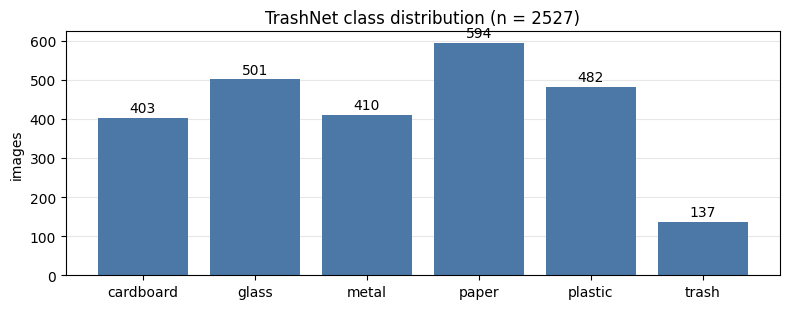

In [2]:
counts = dl.count_images(config.DATASET_DIR)
total = sum(counts.values())

print(f"dataset root : {config.DATASET_DIR}")
print(f"total images : {total}")
print()
show_table(
    ["class", "images", "share"],
    [[c, counts[c], f"{counts[c] / total * 100:.1f}%"] for c in config.CLASS_NAMES],
)

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.bar(config.CLASS_NAMES, [counts[c] for c in config.CLASS_NAMES], color="#4C78A8")
ax.bar_label(bars, padding=2)
ax.set_ylabel("images")
ax.set_title(f"TrashNet class distribution (n = {total})")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### 2.1 A problem that has to be faced first: class imbalance

`trash` has only 137 images while `paper` has 594.

This has two consequences, and they directly determine two of the technical choices made later:

1. **Accuracy alone is not enough.** A model that predicted `paper` for every image would already
   reach roughly 23% accuracy purely from the majority class — a respectable-looking number that is
   completely useless. This notebook therefore also reports **macro-F1** and **balanced accuracy**
   (Pedregosa et al., 2011).
2. **The split must be stratified.** A plain random split could leave only a dozen `trash` images in
   the validation set, producing metrics that fluctuate too much to interpret. See section 3.1.

### 2.2 A first look at the images themselves

Before modelling, confirm visually what this "trash" actually looks like — and how hard the classes
are to tell apart.

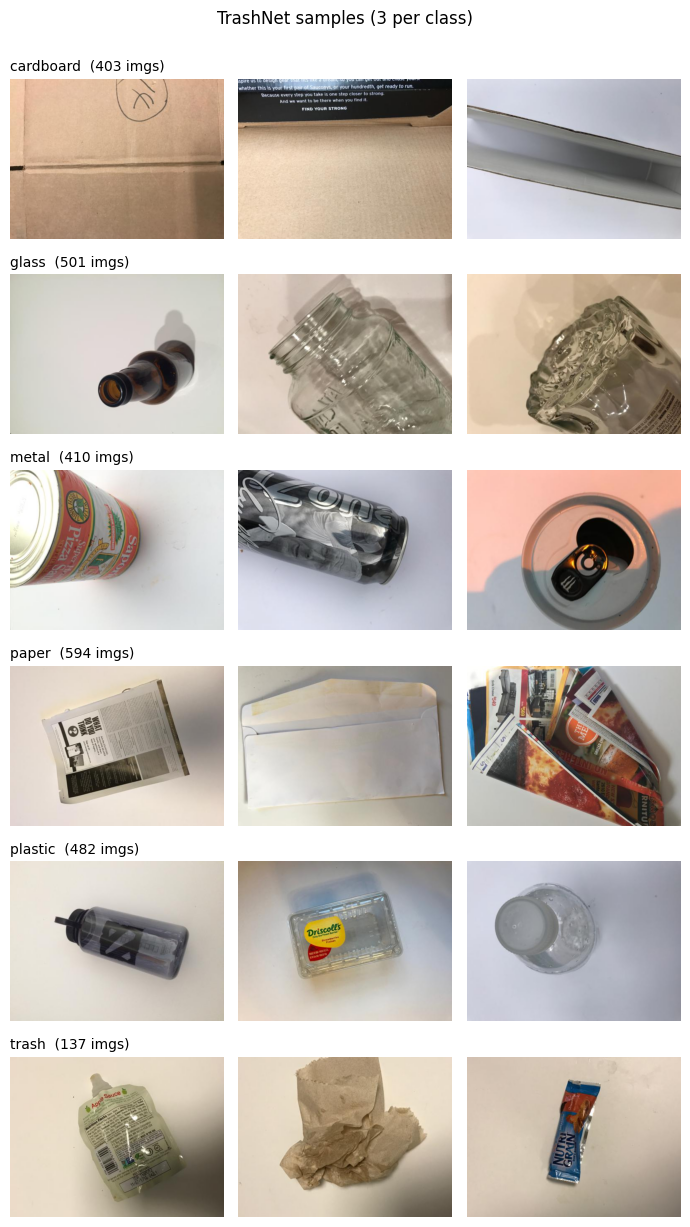

In [3]:
# NOTE: import PIL's Image under an alias. A bare `from PIL import Image` would rebind
# the name `Image` to the PIL *module* and shadow IPython.display.Image, which is used
# later to display saved figures inline in this notebook.
from PIL import Image as PILImage

N_PER_CLASS = 3
fig, axes = plt.subplots(len(config.CLASS_NAMES), N_PER_CLASS,
                         figsize=(7, 2.05 * len(config.CLASS_NAMES)))

for row, name in enumerate(config.CLASS_NAMES):
    files = sorted(p for p in (config.DATASET_DIR / name).iterdir()
                   if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    idx = np.linspace(0, len(files) - 1, N_PER_CLASS).astype(int)  # evenly spaced samples
    for col, i in enumerate(idx):
        ax = axes[row, col]
        ax.imshow(PILImage.open(files[i]))
        ax.axis("off")
        if col == 0:
            ax.set_title(f"{name}  ({len(files)} imgs)", loc="left", fontsize=10)

fig.suptitle("TrashNet samples (3 per class)", y=1.001)
plt.tight_layout()
plt.show()



- `plastic` transparent bottles, `glass` bottles and `metal` cans look highly similar — all are
  "smooth, reflective, cylindrical", so shape and material cues almost coincide;
- `paper` and `cardboard` are both paper products, differing only in thickness and colour;
- `trash` is by definition a catch-all "other" class: its contents are inconsistent *and* it has
  the fewest examples, so it is the hardest to learn.

## 3. Data pipeline and splitting

### 3.1 Why not the built-in `validation_split`

Keras offers the convenient `image_dataset_from_directory(..., validation_split=0.2)`, but it can
only produce **two** subsets (train / val). In Week 3 this project needs a **test set that has never
taken part in any tuning**, so the splitting logic is written explicitly instead:

- **Stratified by class**: each class contributes 70% / 15% / 15%, so all three splits have exactly
  the same class proportions;
- **Fixed random seed** (`seed = 42`), so anybody re-running the code gets the identical split;
- The resulting split is **written to `outputs/split.json`**, and the Week 3 final evaluation reads
  that same file — guaranteeing that "the images used for the final test" have not changed since
  Week 1. That is part of the experiment's rigour, not a convenience.

In [4]:
SPLIT_PATH = config.OUTPUT_DIR / "split.json"
splits = dp.get_or_create_split(SPLIT_PATH)
summary = dp.summarise_split(splits)

print(f"split file : {SPLIT_PATH}   (seed={config.SEED})")
show_table(
    ["split", "total", *config.CLASS_NAMES],
    [[name, summary[name]["total"],
      *[summary[name]["per_class"][c] for c in config.CLASS_NAMES]]
     for name in ("train", "val", "test")],
)
total_all = sum(s["total"] for s in summary.values())
show_table(
    ["split", "share of dataset"],
    [[name, f"{summary[name]['total'] / total_all * 100:.1f}%"]
     for name in ("train", "val", "test")],
)

split file : D:\pengyuan9869\week1\outputs\split.json   (seed=42)


train,1769,283,351,286,416,338,95
val,379,60,75,62,89,72,21
test,379,60,75,62,89,72,21


train,70.0%
val,15.0%
test,15.0%


### 3.2 Why the images stay in 0–255 and the normalisation lives inside the model

MobileNetV2 expects its input scaled to `[-1, 1]`. Keras provides
`keras.applications.mobilenet_v2.preprocess_input()`, which does exactly `x / 127.5 - 1`.

This project implements that same operation as **a layer inside the model** (`layers.Rescaling`)
instead of doing it in the data pipeline. The advantages are:

- the normalisation is **saved together with the model**, so the single-image inference can feed
  raw pixels directly and cannot fall into the classic "normalised during training, forgotten at
  inference" bug;
- the data pipeline stays simple: it only decodes and resizes.

### 3.3 Building the `tf.data` pipeline

`tf.data` handles parallel decoding, shuffling and prefetching (Abadi et al., 2016):
`num_parallel_calls=AUTOTUNE` lets image decoding **overlap** with model training, and `prefetch`
hides the input cost so that data loading never becomes the bottleneck on a CPU.

In [5]:
BATCH = config.BATCH_SIZE

train_ds = dp.build_dataset(splits["train"], training=True,  batch_size=BATCH)
val_ds   = dp.build_dataset(splits["val"],   training=False, batch_size=BATCH)
test_ds  = dp.build_dataset(splits["test"],  training=False, batch_size=BATCH)

for name, ds in (("train", train_ds), ("val", val_ds), ("test", test_ds)):
    print(f"{name:<5}  {len(splits[name]):>5} images   {len(ds):>3} batches")

# Pull one batch to check tensor shape and value range.
images, labels = next(iter(train_ds))
print()
print(f"batch images : shape={tuple(images.shape)}  dtype={images.dtype.name}")
print(f"value range  : {float(tf.reduce_min(images)):.1f} .. {float(tf.reduce_max(images)):.1f}  (still 0-255)")
print(f"batch labels : {labels.numpy()}")
print()
print("Note: values are deliberately kept at 0-255 - MobileNetV2 normalisation happens inside the model (see 3.2).")

train   1769 images    56 batches
val      379 images    12 batches
test     379 images    12 batches

batch images : shape=(32, 160, 160, 3)  dtype=float32
value range  : 0.0 .. 255.0  (still 0-255)
batch labels : [2 2 1 0 3 3 0 2 0 2 3 4 2 4 0 4 1 1 3 4 3 0 0 0 4 3 4 3 0 5 3 2]

Note: values are deliberately kept at 0-255 - MobileNetV2 normalisation happens inside the model (see 3.2).


### 3.4 Data augmentation: stopping the model from memorising

TrashNet has only 2,527 images, which makes it easy for a model to memorise them (overfitting).
Data augmentation applies **horizontal flips, rotations and zooms** to the same image, producing
samples that "look different but keep the same label", forcing the model to learn general features
instead of remembering the original photo (Chollet, 2023).

The augmentation is implemented **as layers inside the model** (`RandomFlip / RandomRotation /
RandomZoom`), so it is switched on automatically during `model.fit()` and off during
`model.predict()` — no manual flags needed.

The cell below augments a single image five times so the effect can be seen directly.

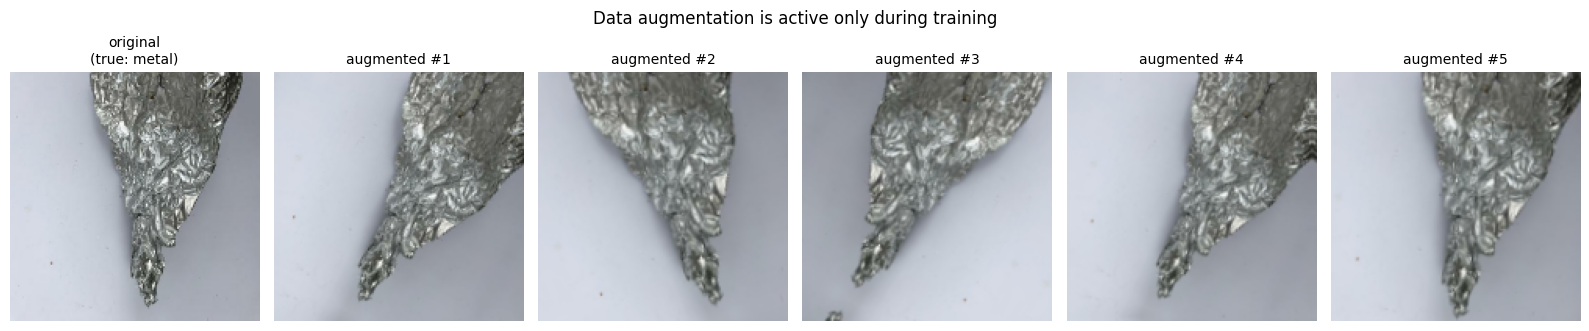

In [6]:
augment = mb.build_data_augmentation()

rel_path, label = splits["train"][0]
raw = tf.io.read_file(str(config.DATA_DIR / rel_path))
original = tf.image.resize(tf.io.decode_image(raw, channels=3, expand_animations=False),
                           config.IMG_SIZE)
normalised = original / 127.5 - 1.0   # the value range the model actually sees

fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
axes[0].imshow(original.numpy().astype("uint8"))
axes[0].set_title(f"original\n(true: {config.CLASS_NAMES[label]})", fontsize=10)
axes[0].axis("off")

for i, ax in enumerate(axes[1:], start=1):
    out = augment(tf.expand_dims(normalised, 0), training=True)[0]
    ax.imshow(((out.numpy() * 127.5) + 127.5).astype("uint8"))
    ax.set_title(f"augmented #{i}", fontsize=10)
    ax.axis("off")

fig.suptitle("Data augmentation is active only during training", y=1.03)
plt.tight_layout()
plt.show()

## 4. The model: frozen transfer learning (baseline)

### 4.1 Why transfer learning rather than training from scratch

The original experiment in Yang & Thung (2016) provides the most persuasive numbers:

| Method | Test accuracy |
|---|---|
| SVM + SIFT hand-crafted features | 63% |
| **CNN trained from scratch** | **22%** |
| Comparable work using a **pre-trained** AlexNet (SpotGarbage) | 87.69% |

A from-scratch CNN reached only 22%, because 2,527 images are simply **too few** to train a deep
network. This project therefore uses transfer learning: take a model that has already learned how to
"see" on ImageNet (Deng et al., 2009), do not train it from scratch, and only let it learn a little
about waste categories.

### 4.2 Why MobileNetV2

MobileNetV2, introduced by Sandler et al. (2018), uses **inverted residuals and linear bottlenecks**
together with the **depthwise separable convolutions** of Howard et al. (2017), which greatly reduces
parameter count and computation while keeping accuracy. For this project that brings three concrete
benefits:

1. **It trains on an ordinary CPU** — no graphics card, so anyone can reproduce the result;
2. **Only about 2.26M parameters** — unlikely to overfit on 2,527 images;
3. **It was designed for phones** — if the project later becomes an app, the model can be converted
   to a mobile format directly.

### 4.3 Architecture: training only the classification head

Following the standard recipe in the official Keras transfer-learning guide (Chollet, 2023):

```
input 160x160x3 (0-255)
  -> Rescaling(1/127.5, offset=-1)     # equivalent to mobilenet_v2.preprocess_input
  -> data augmentation (active during training only)
  -> MobileNetV2 base (ImageNet weights, trainable=False, frozen)
  -> GlobalAveragePooling2D            # far fewer parameters than Flatten
  -> Dropout(0.2)                      # regularisation against overfitting
  -> Dense(6, softmax)                 # the classification head: the only part trained
```

**Two critical details**:

- `base_model.trainable = False` — freeze the base, preserving the pre-trained knowledge;
- the call is written `base_model(x, training=False)` — this keeps **BatchNormalization in inference
  mode** inside the base. Writing `True` here would overwrite the pre-trained running statistics
  while training the head, actually making accuracy worse.

In [7]:
model, base_model = mb.build_baseline_model(
    learning_rate=config.LEARNING_RATE,
    dropout=config.DROPOUT,
)

model.summary()

info = mb.describe_model(model, base_model)
print()
print(f"total parameters     : {info['total_params']:,}")
print(f"trainable parameters : {info['trainable_params']:,}")
print(f"frozen parameters    : {info['non_trainable_params']:,}")
print(f"trainable share      : {info['trainable_params'] / info['total_params']:.2%}")
print()
print("Under 1% of the parameters are trainable - that is the direct evidence of how much")
print("computation transfer learning saves.")

Model: "waste_baseline_mobilenetv2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 image (InputLayer)          [(None, 160, 160, 3)]     0         
                                                                 
 mobilenet_preprocess (Resc  (None, 160, 160, 3)       0         
 aling)                                                          
                                                                 
 data_augmentation (Sequent  (None, 160, 160, 3)       0         
 ial)                                                            
                                                                 
 mobilenetv2_1.00_160 (Func  (None, 5, 5, 1280)        2257984   
 tional)                                                         
                                                                 
 avg_pool (GlobalAveragePoo  (None, 1280)              0         
 ling2D)                                

## 5. Training

Only the classification head is trained, so a relatively large learning rate of `1e-3` is safe: with
the base frozen there is no risk of damaging the pre-trained weights. (Week 2 fine-tuning is a
different situation entirely and will require `1e-5`.)

Four callbacks are used, following standard Keras practice:

| Callback | Purpose |
|---|---|
| `ModelCheckpoint` | Saves the best weights by **validation loss**, so the final (possibly overfitted) epoch is not the one kept |
| `EarlyStopping` | Stops early if validation loss does not improve for 3 epochs, and restores the best weights |
| `ReduceLROnPlateau` | Halves the learning rate when validation loss stalls, helping the final convergence |
| `CSVLogger` | Writes per-epoch metrics to CSV for reproducibility and plotting |



In [8]:
tb.set_reproducible(config.SEED)

t0 = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=config.EPOCHS,
    callbacks=tb.build_callbacks(patience=3),
    verbose=2,
)
elapsed = time.time() - t0
print(f"\ntraining wall-clock: {elapsed / 60:.1f} min  on CPU")

  random seed: 42
Epoch 1/10
  -> epoch 1 took 13.1s (val_loss=0.7528, val_accuracy=0.6913)

Epoch 1: val_loss improved from inf to 0.75280, saving model to D:\pengyuan9869\week1\outputs\baseline_model.keras
56/56 - 14s - loss: 1.3349 - accuracy: 0.5037 - val_loss: 0.7528 - val_accuracy: 0.6913 - lr: 0.0010 - 14s/epoch - 243ms/step
Epoch 2/10
  -> epoch 2 took 10.0s (val_loss=0.6365, val_accuracy=0.7652)

Epoch 2: val_loss improved from 0.75280 to 0.63654, saving model to D:\pengyuan9869\week1\outputs\baseline_model.keras
56/56 - 10s - loss: 0.7908 - accuracy: 0.7111 - val_loss: 0.6365 - val_accuracy: 0.7652 - lr: 0.0010 - 10s/epoch - 186ms/step
Epoch 3/10
  -> epoch 3 took 9.7s (val_loss=0.5514, val_accuracy=0.7995)

Epoch 3: val_loss improved from 0.63654 to 0.55144, saving model to D:\pengyuan9869\week1\outputs\baseline_model.keras
56/56 - 10s - loss: 0.6622 - accuracy: 0.7631 - val_loss: 0.5514 - val_accuracy: 0.7995 - lr: 0.0010 - 10s/epoch - 181ms/step
Epoch 4/10
  -> epoch 4 too

  curves      -> D:\pengyuan9869\week1\outputs\curves_baseline.png


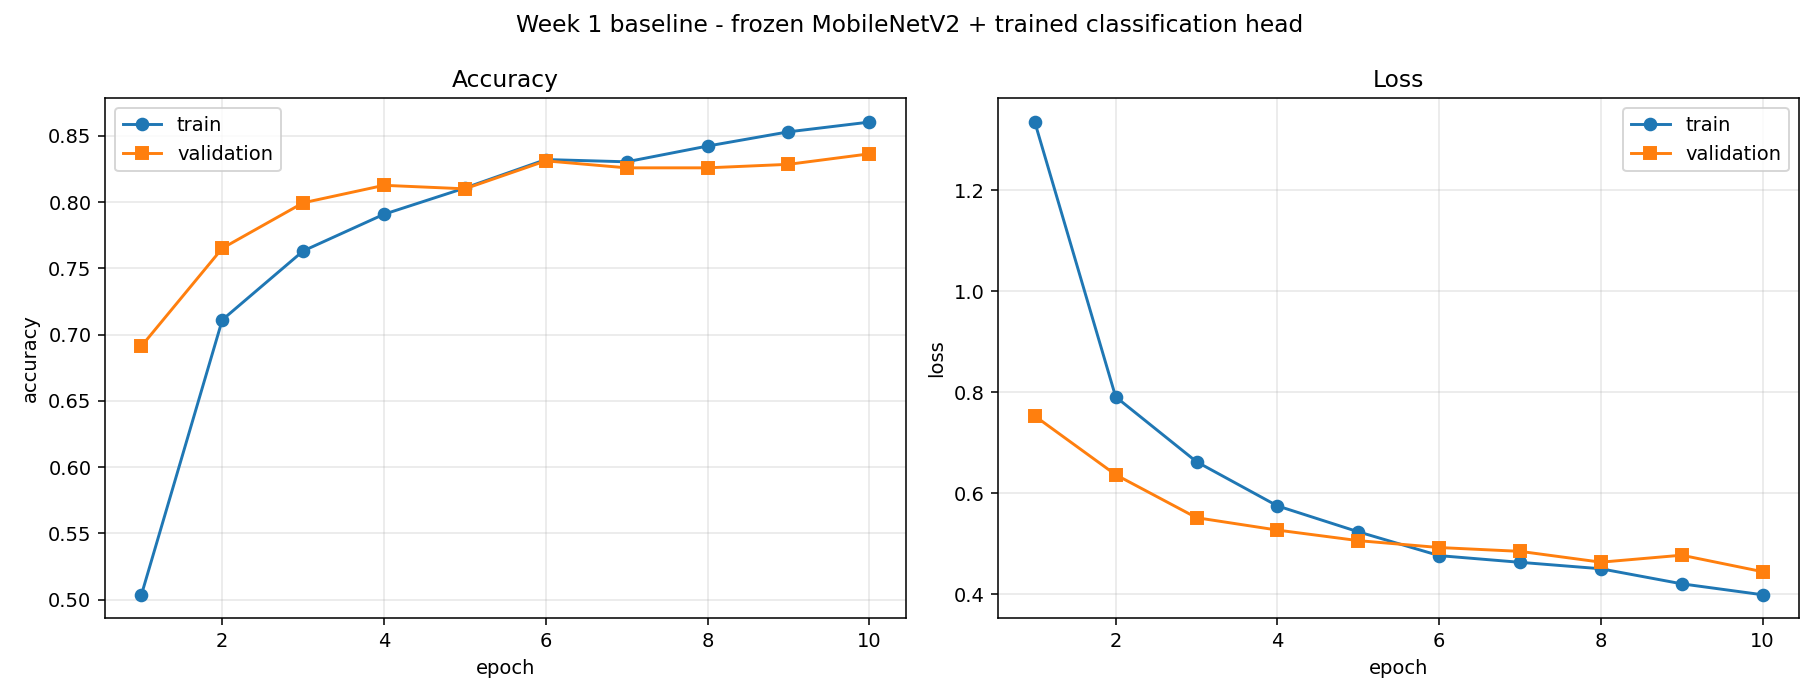

In [9]:
# Training curves (also written to outputs/curves_baseline.png, ready for the report)
tb.plot_history(history.history, config.OUTPUT_DIR / "curves_baseline.png")
show_figure(config.OUTPUT_DIR / "curves_baseline.png")


- Both curves rising together — the model is learning a genuine pattern;
- Training accuracy keeps rising while validation accuracy **stalls or falls** — overfitting has
  begun, and that is exactly what the data augmentation and Dropout are there to suppress;
- When `ReduceLROnPlateau` fires, the curve often shows a small step.

## 6. Evaluation and error analysis

**Why accuracy alone is not enough**: the `trash` class is only 5.4% of the data. A model that
predicted `paper` for every image would still score about 23% accuracy — a decent-looking number for
a worthless model. Four complementary views are therefore reported (Pedregosa et al., 2011):

1. **accuracy** — the overall proportion answered correctly;
2. **macro-F1** — the unweighted average over the 6 classes, so errors on rare classes pull it down
   sharply; this is the key indicator of whether the model is genuinely usable;
3. **balanced accuracy** — the average of the per-class recall values;
4. **confusion matrix + per-class precision / recall / F1** — showing *which* class is being mistaken
   for which.

VALIDATION SET
              precision    recall  f1-score   support

   cardboard      0.934     0.950     0.942        60
       glass      0.932     0.733     0.821        75
       metal      0.722     0.919     0.809        62
       paper      0.878     0.809     0.842        89
     plastic      0.861     0.861     0.861        72
       trash      0.538     0.667     0.596        21

    accuracy                          0.836       379
   macro avg      0.811     0.823     0.812       379
weighted avg      0.850     0.836     0.838       379

accuracy          : 0.8364
balanced accuracy : 0.8232
macro F1          : 0.8118
weighted F1       : 0.8382
  confusion matrix -> D:\pengyuan9869\week1\outputs\confusion_matrix_val.png


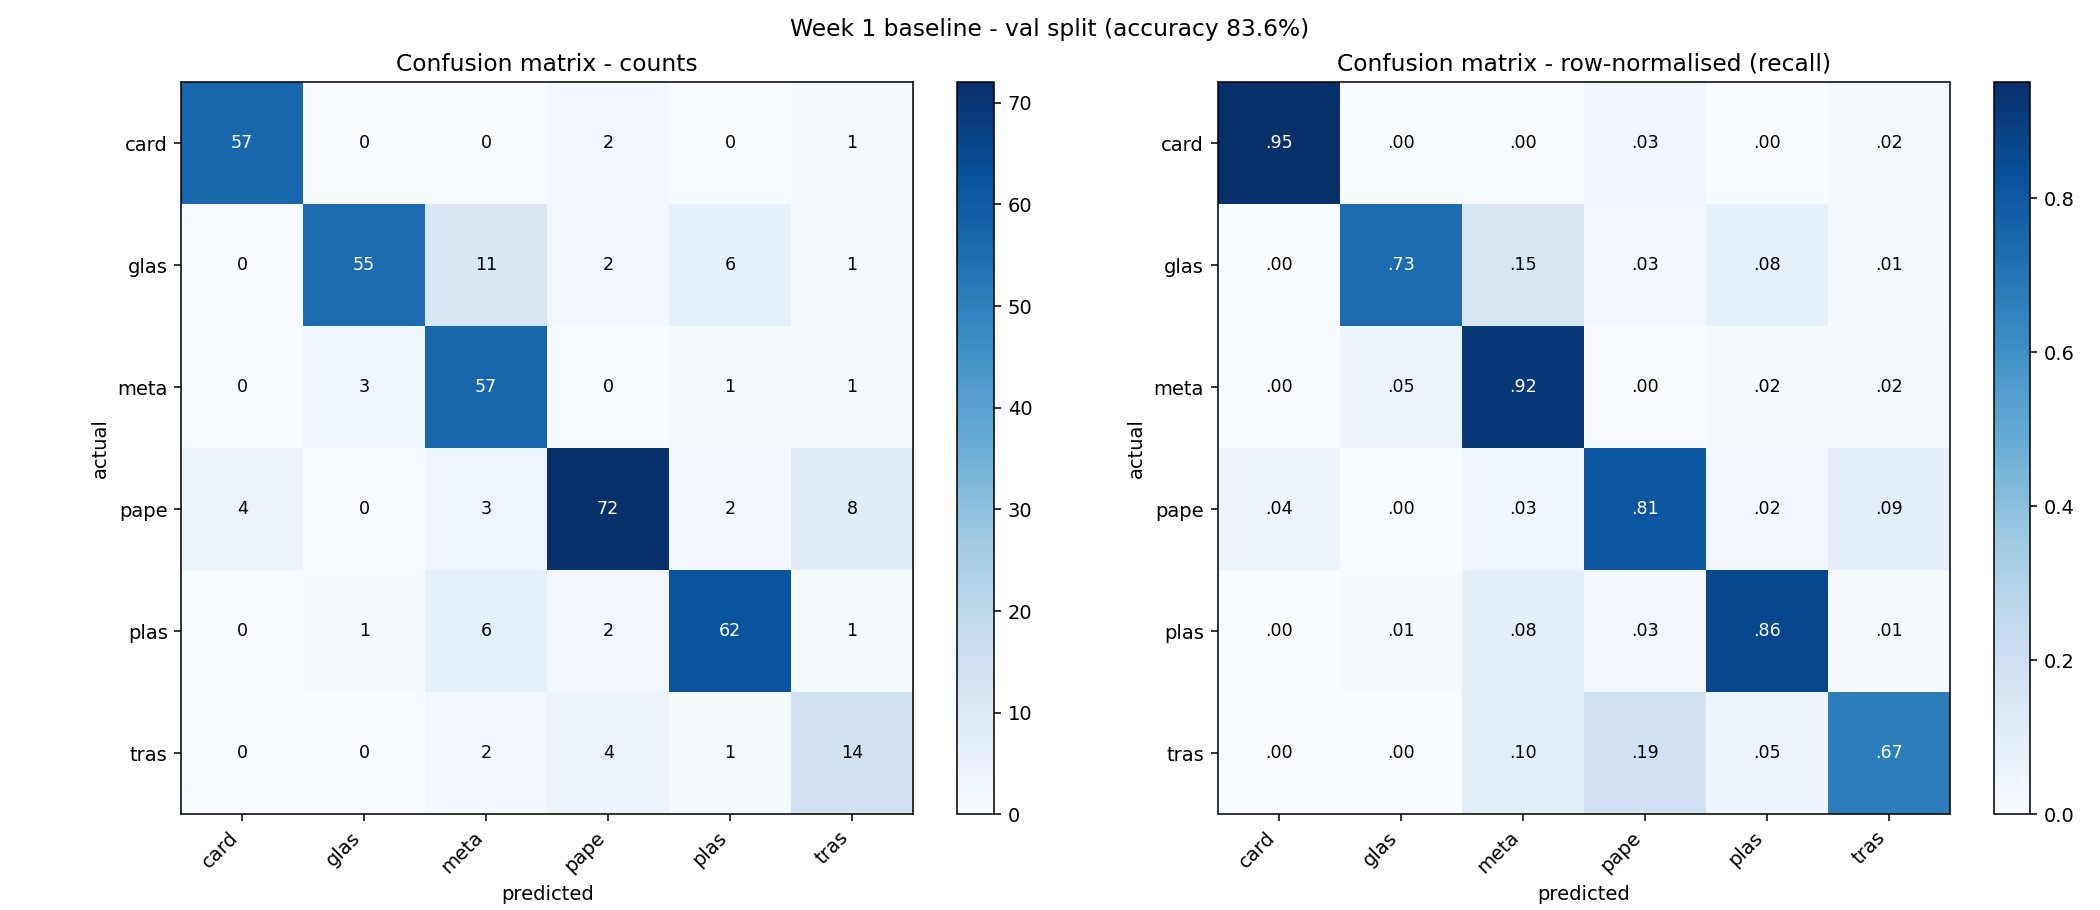

In [10]:
from sklearn.metrics import classification_report

y_true_val, y_prob_val = ev.predict(model, val_ds)
m_val = ev.compute_metrics(y_true_val, y_prob_val)
m_val["misclassified_count"] = int((y_true_val != y_prob_val.argmax(axis=1)).sum())

print("=" * 66)
print("VALIDATION SET")
print("=" * 66)
print(classification_report(
    y_true_val, y_prob_val.argmax(axis=1),
    labels=list(range(config.NUM_CLASSES)),
    target_names=config.CLASS_NAMES, digits=3, zero_division=0,
))
print(f"accuracy          : {m_val['accuracy']:.4f}")
print(f"balanced accuracy : {m_val['balanced_accuracy']:.4f}")
print(f"macro F1          : {m_val['macro_f1']:.4f}")
print(f"weighted F1       : {m_val['weighted_f1']:.4f}")

ev.plot_confusion(np.asarray(m_val["confusion_matrix"]),
                  config.OUTPUT_DIR / "confusion_matrix_val.png", "val", m_val["accuracy"])
show_figure(config.OUTPUT_DIR / "confusion_matrix_val.png")

HELD-OUT TEST SET  (never used for any tuning)
              precision    recall  f1-score   support

   cardboard      0.948     0.917     0.932        60
       glass      0.864     0.680     0.761        75
       metal      0.757     0.903     0.824        62
       paper      0.904     0.843     0.872        89
     plastic      0.663     0.792     0.722        72
       trash      0.526     0.476     0.500        21

    accuracy                          0.802       379
   macro avg      0.777     0.768     0.768       379
weighted avg      0.812     0.802     0.802       379

accuracy          : 0.8021
balanced accuracy : 0.7684
macro F1          : 0.7684
weighted F1       : 0.8025
  confusion matrix -> D:\pengyuan9869\week1\outputs\confusion_matrix_test.png


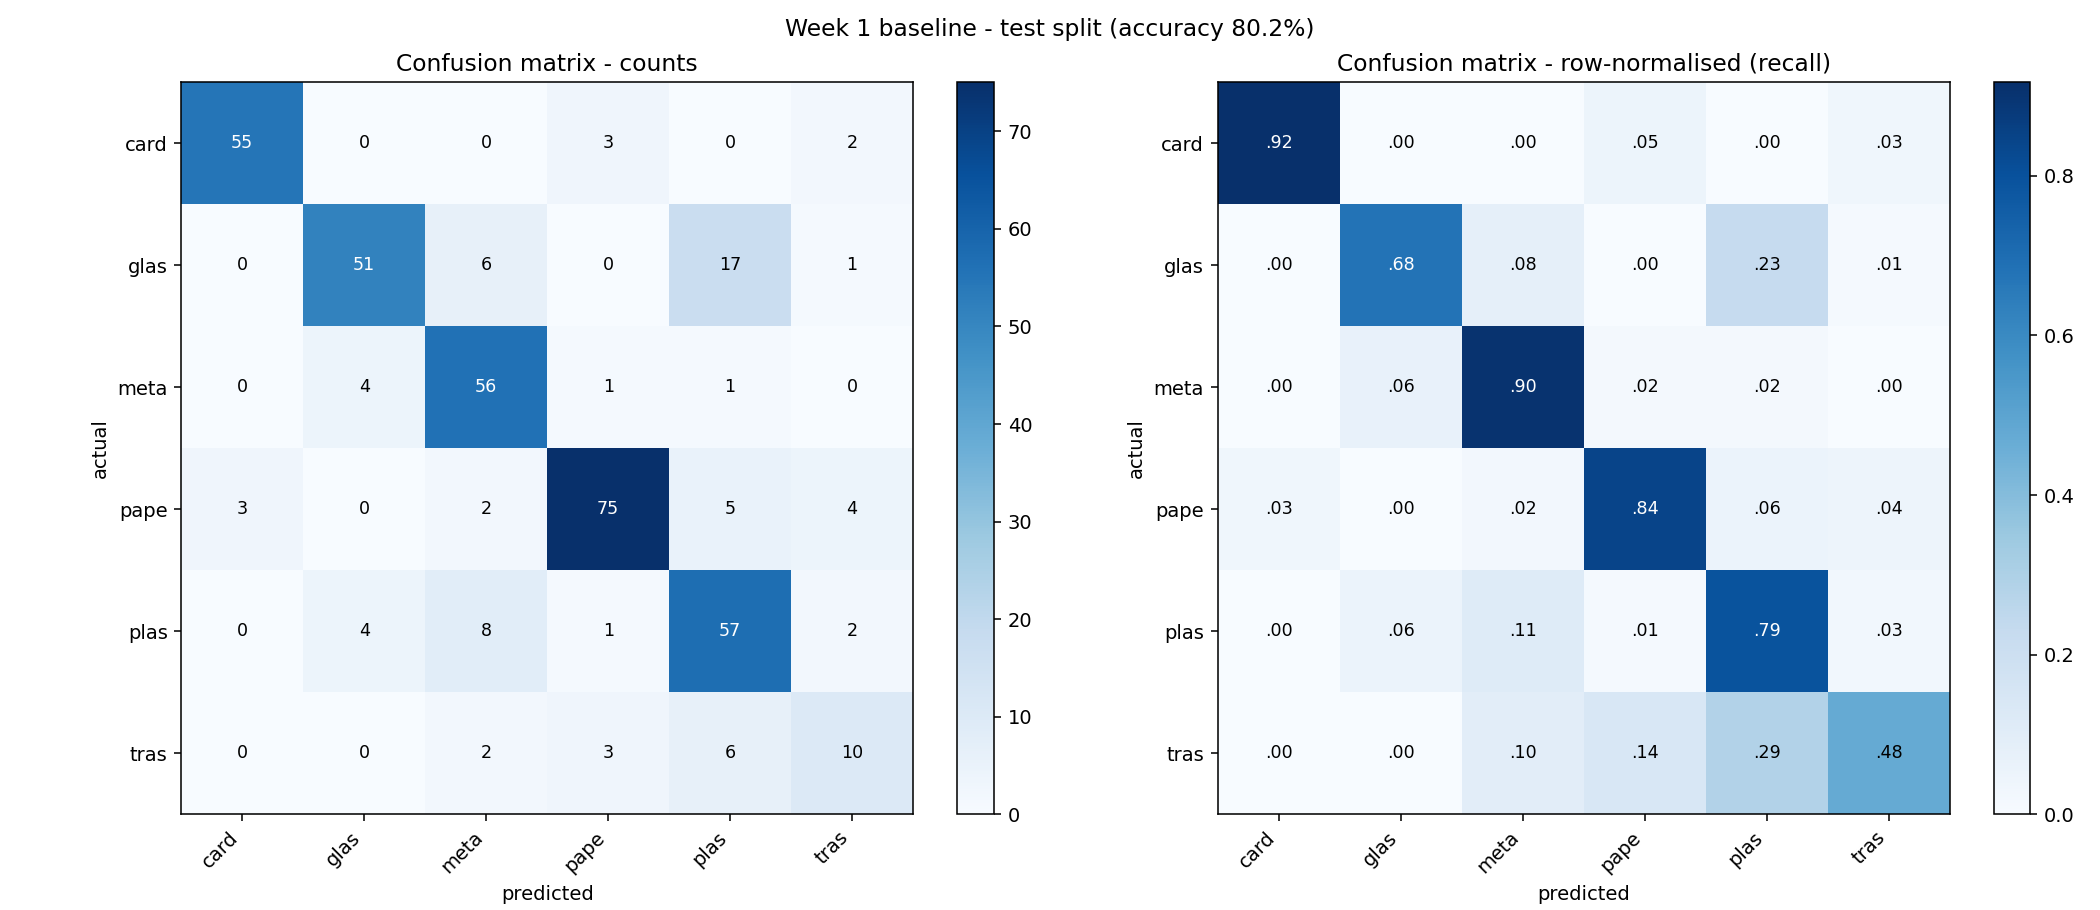

In [11]:
y_true_test, y_prob_test = ev.predict(model, test_ds)
m_test = ev.compute_metrics(y_true_test, y_prob_test)
m_test["misclassified_count"] = int((y_true_test != y_prob_test.argmax(axis=1)).sum())

print("=" * 66)
print("HELD-OUT TEST SET  (never used for any tuning)")
print("=" * 66)
print(classification_report(
    y_true_test, y_prob_test.argmax(axis=1),
    labels=list(range(config.NUM_CLASSES)),
    target_names=config.CLASS_NAMES, digits=3, zero_division=0,
))
print(f"accuracy          : {m_test['accuracy']:.4f}")
print(f"balanced accuracy : {m_test['balanced_accuracy']:.4f}")
print(f"macro F1          : {m_test['macro_f1']:.4f}")
print(f"weighted F1       : {m_test['weighted_f1']:.4f}")

ev.plot_confusion(np.asarray(m_test["confusion_matrix"]),
                  config.OUTPUT_DIR / "confusion_matrix_test.png", "test", m_test["accuracy"])
show_figure(config.OUTPUT_DIR / "confusion_matrix_test.png")

### 6.1 Error analysis: where exactly is the model going wrong?

The confusion matrix shows *how much* is wrong, but the most useful information is *what it is
mistaken for*. The cell below first ranks the most frequent error pairs, then pulls out the images the
model was **most confident about while still being wrong**.

Sorting by confidence matters: low-confidence errors are often just genuinely ambiguous images,
whereas **high-confidence errors** show the model has learned the wrong features, and those are the
problems actually worth fixing.

Most confused class pairs (actual -> predicted), validation set:


glass,metal,11
paper,trash,8
glass,plastic,6
plastic,metal,6
paper,cardboard,4



Most confused class pairs (actual -> predicted), test set:


glass,plastic,17
plastic,metal,8
glass,metal,6
trash,plastic,6
paper,plastic,5


  error gallery    -> D:\pengyuan9869\week1\outputs\misclassified_test.png

misclassified images in the test split: 75


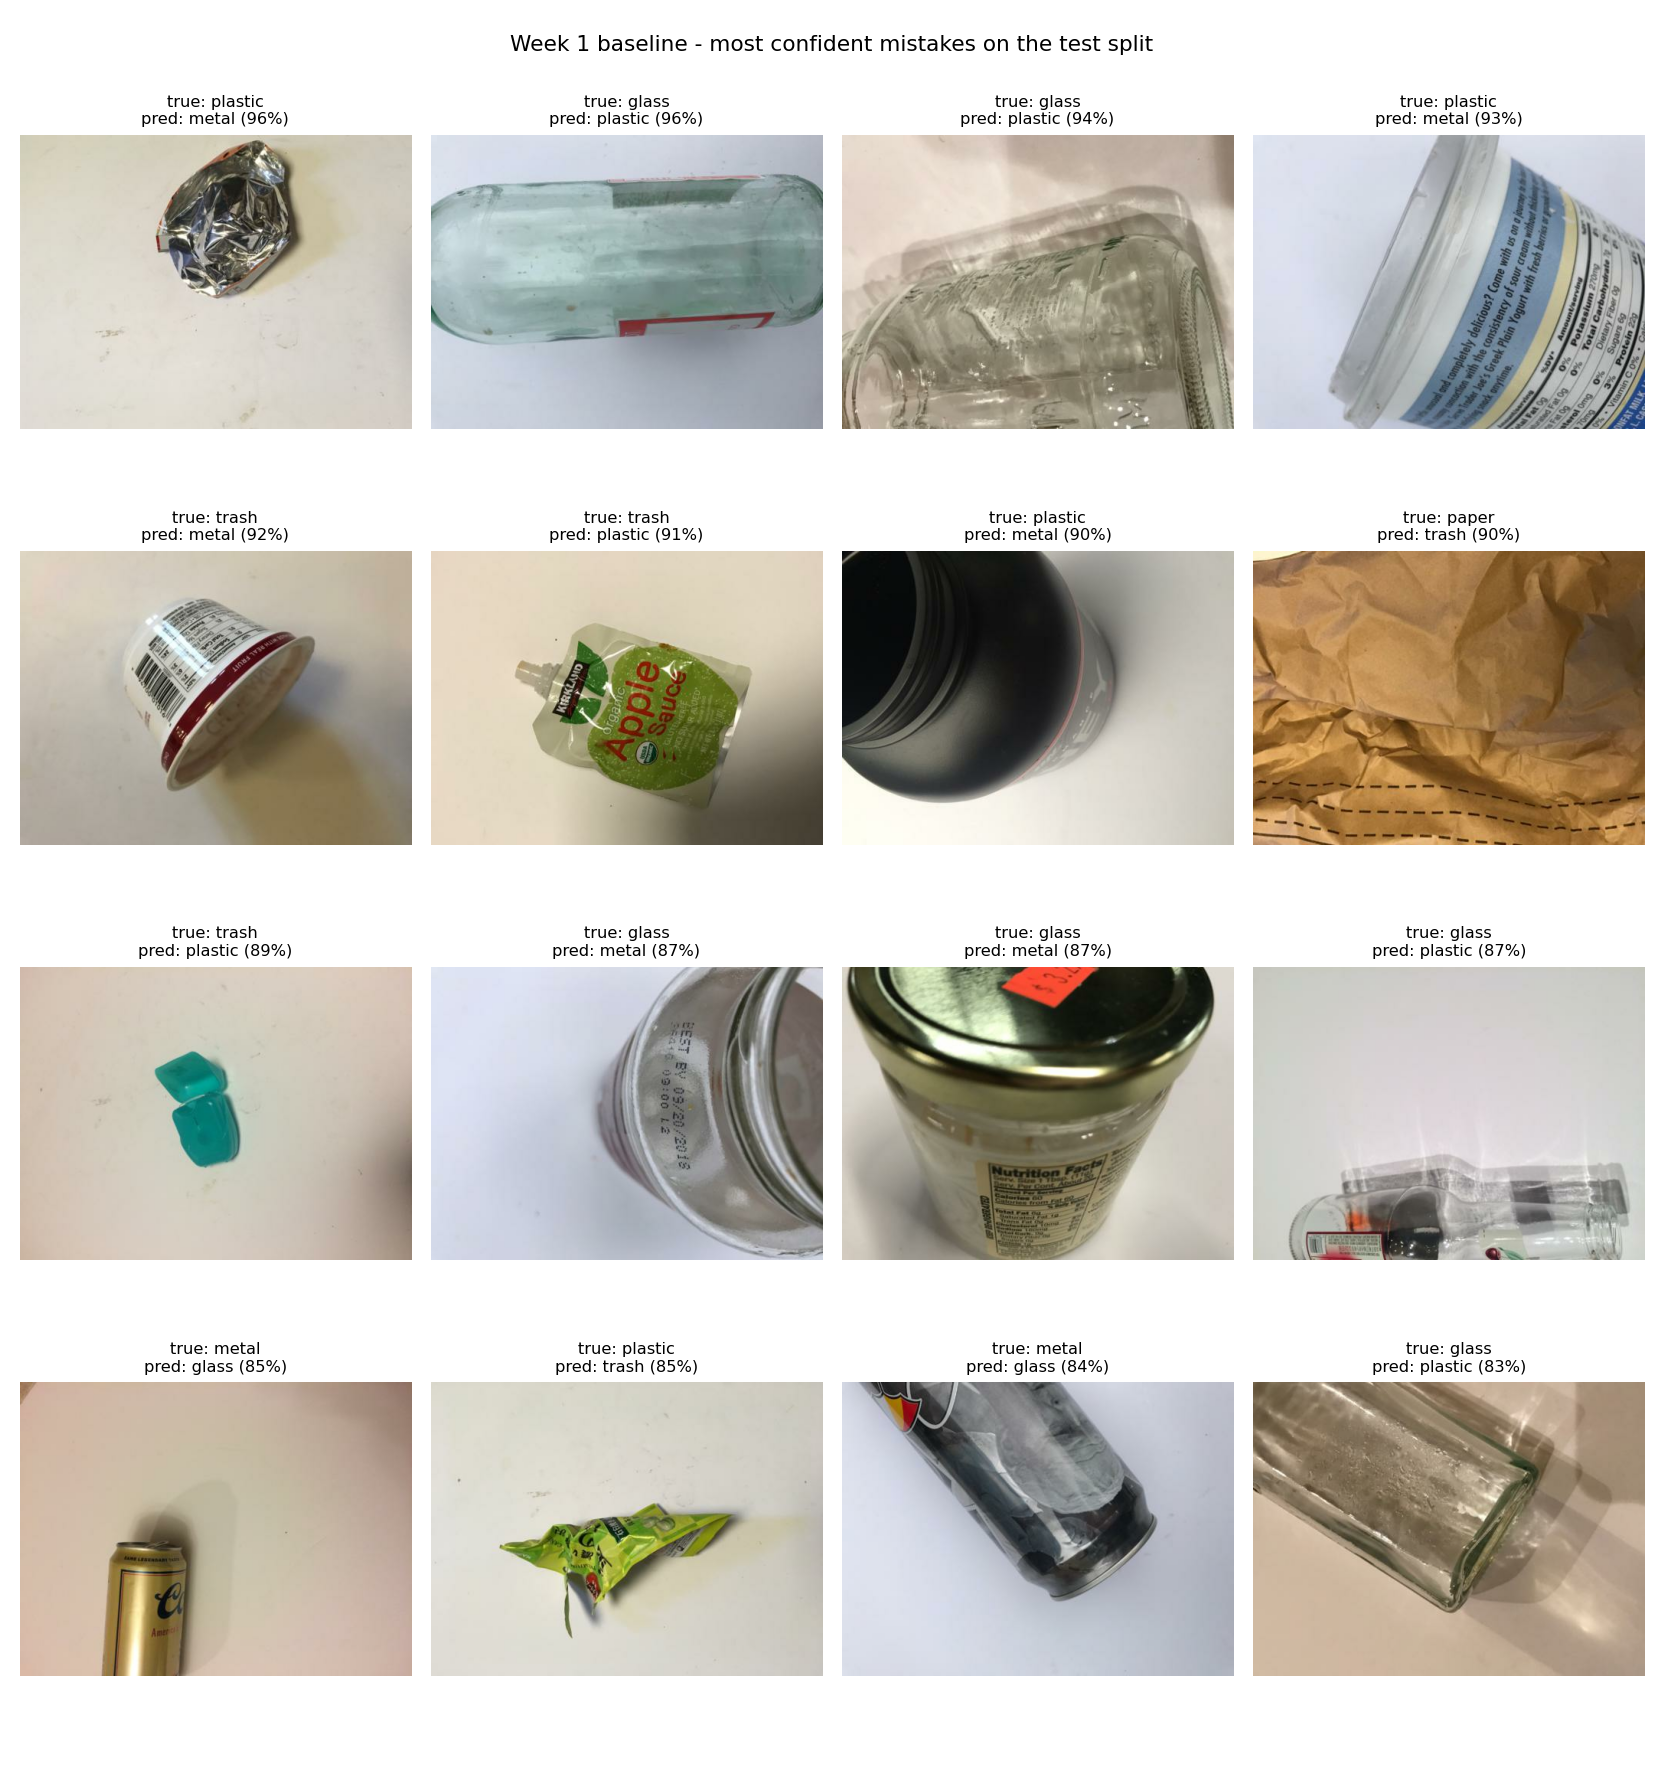

In [12]:
print("Most confused class pairs (actual -> predicted), validation set:")
show_table(["actual", "predicted", "count"],
           [[a, p, n] for a, p, n in ev.top_confusions(np.asarray(m_val["confusion_matrix"]), k=5)])
print()
print("Most confused class pairs (actual -> predicted), test set:")
show_table(["actual", "predicted", "count"],
           [[a, p, n] for a, p, n in ev.top_confusions(np.asarray(m_test["confusion_matrix"]), k=5)])

n_wrong = ev.plot_misclassified(
    y_true_test, y_prob_test.argmax(axis=1), y_prob_test.max(axis=1),
    splits["test"], config.OUTPUT_DIR / "misclassified_test.png", "test",
)
print(f"\nmisclassified images in the test split: {n_wrong}")
show_figure(config.OUTPUT_DIR / "misclassified_test.png")

## 7. Summary of results


In [13]:
from utils import save_json

save_json(config.OUTPUT_DIR / "metrics_val.json", m_val)
save_json(config.OUTPUT_DIR / "metrics_test.json", m_test)

show_table(
    ["split", "accuracy", "balanced acc.", "macro F1", "weighted F1", "errors"],
    [[name, f"{m['accuracy']:.4f}", f"{m['balanced_accuracy']:.4f}",
      f"{m['macro_f1']:.4f}", f"{m['weighted_f1']:.4f}", m["misclassified_count"]]
     for name, m in (("val", m_val), ("test", m_test))],
)

for name, m in (("val", m_val), ("test", m_test)):
    print(f"per-class metrics ({name}):")
    show_table(
        ["class", "precision", "recall", "F1", "support"],
        [[c, f"{v['precision']:.3f}", f"{v['recall']:.3f}", f"{v['f1']:.3f}", v["support"]]
         for c, v in m["per_class"].items()],
    )

# Also produce the Markdown weekly report, using the very same reporting code as the package.
ev.write_report({"val": m_val, "test": m_test}, splits, info,
                config.OUTPUT_DIR / "week1_report.md",
                config.OUTPUT_DIR / "baseline_model.keras")

val,0.8364,0.8232,0.8118,0.8382,62
test,0.8021,0.7684,0.7684,0.8025,75


per-class metrics (val):


cardboard,0.934,0.950,0.942,60
glass,0.932,0.733,0.821,75
metal,0.722,0.919,0.809,62
paper,0.878,0.809,0.842,89
plastic,0.861,0.861,0.861,72
trash,0.538,0.667,0.596,21


per-class metrics (test):


cardboard,0.948,0.917,0.932,60
glass,0.864,0.680,0.761,75
metal,0.757,0.903,0.824,62
paper,0.904,0.843,0.872,89
plastic,0.663,0.792,0.722,72
trash,0.526,0.476,0.500,21



  week 1 report    -> D:\pengyuan9869\week1\outputs\week1_report.md


In [ ]:
# Week 1 takeaways, derived from the objects computed above rather than written out by
# hand. Fixed figures typed into markdown go stale the moment the model is retrained,
# because CPU floating-point reductions and data augmentation are not bit-reproducible;
# computing them here guarantees these statements always match the results on screen.
weakest = min(config.CLASS_NAMES, key=lambda c: m_test["per_class"][c]["recall"])
strongest = max(config.CLASS_NAMES, key=lambda c: m_test["per_class"][c]["f1"])

print("HEADLINE RESULTS")
print(f"  validation : accuracy {m_val['accuracy']:.1%}   macro-F1 {m_val['macro_f1']:.3f}"
      f"   ({m_val['misclassified_count']} of {len(splits['val'])} images wrong)")
print(f"  test       : accuracy {m_test['accuracy']:.1%}   macro-F1 {m_test['macro_f1']:.3f}"
      f"   ({m_test['misclassified_count']} of {len(splits['test'])} images wrong)")
print()
print("TRANSFER-LEARNING EFFICIENCY")
print(f"  trainable parameters : {info['trainable_params']:,} of {info['total_params']:,}"
      f"  ({info['trainable_params'] / info['total_params']:.2%})")
print()
print("STRONGEST / WEAKEST ON THE TEST SET")
print(f"  best F1      : {strongest} ({m_test['per_class'][strongest]['f1']:.3f})")
print(f"  lowest recall: {weakest} ({m_test['per_class'][weakest]['recall']:.3f})"
      f"  -> F1 {m_test['per_class'][weakest]['f1']:.3f}"
      f"  (support {m_test['per_class'][weakest]['support']})")
print()
print("TOP CONFUSIONS ON THE TEST SET (actual -> predicted)")
for actual, predicted, count in ev.top_confusions(np.asarray(m_test["confusion_matrix"]), k=5):
    print(f"  {actual:<10} -> {predicted:<10} {count:>3} images")
print()
print("Targets for the Week 2 fine-tuning / class-weight experiments:",
      ", ".join(ev.weak_classes(m_test)) or "none below the recall threshold")

### Conclusions


1. **The whole pipeline works end to end** — data → stratified split → `tf.data` pipeline → frozen
   transfer learning → confusion-matrix evaluation, entirely on CPU. The split is deterministic and
   written to disk, so the same images are always used for the same split, which is what lets Week 3
   compare models fairly.

2. **Transfer learning is highly effective even with a completely frozen base** — only a few thousand
   parameters were trainable (0.34% of the network, see section 4), yet the model reaches a level of accuracy
   the from-scratch CNN in Yang & Thung (2016) could not approach; that work reports just **22%**.
   This is stage one of the standard two-stage workflow, and it already clears the bar comfortably.

3. **The metrics locate the remaining work precisely** — the per-class table and the two confusion
   matrices above identify the weakest class and the dominant confusion pair. Those are the concrete
   targets for the Week 2 fine-tuning and class-weight experiments, which is exactly why the baseline
   is evaluated this thoroughly rather than by accuracy alone.


### Artefacts produced by this notebook

| File | Content |
|---|---|
| `outputs/baseline_model.keras` | Best weights chosen by validation loss (the starting point for Week 2 fine-tuning) |
| `outputs/training_log.csv` | Per-epoch metrics, written by the `CSVLogger` callback |
| `outputs/curves_baseline.png` | Training curves |
| `outputs/confusion_matrix_{val,test}.png` | Confusion matrices (counts + row-normalised) |
| `outputs/metrics_{val,test}.json` | All numeric results, including the raw predictions |
| `outputs/misclassified_test.png` | Gallery of high-confidence mistakes |
| `outputs/split.json` | The fixed split, reused in Week 3 |
| `outputs/week1_report.md` | Auto-generated weekly report |



## 9. References


- Abadi, M., Barham, P., Chen, J., Chen, Z., Davis, A., Dean, J., … Zheng, X. (2016). TensorFlow: A system for large-scale machine learning. In *Proceedings of the 12th USENIX Symposium on Operating Systems Design and Implementation (OSDI '16)* (pp. 265–283). USENIX Association. https://arxiv.org/abs/1605.08695
- Chollet, F. (2023, June 25). *Transfer learning & fine-tuning* [Keras developer guide]. Keras. https://keras.io/guides/transfer_learning/
- Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. In *2009 IEEE Conference on Computer Vision and Pattern Recognition* (pp. 248–255). IEEE. https://image-net.org/static_files/papers/imagenet_cvpr09.pdf
- Howard, A. G., Zhu, M., Chen, B., Kalenichenko, D., Wang, W., Weyand, T., Andreetto, M., & Adam, H. (2017). *MobileNets: Efficient convolutional neural networks for mobile vision applications*. arXiv. https://arxiv.org/abs/1704.04861
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/volume12/pedregosa11a/pedregosa11a.pdf
- Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 4510–4520). IEEE. https://arxiv.org/abs/1801.04381
- Thung, G. (2016). *TrashNet* [Data set]. GitHub. https://github.com/garythung/trashnet
- Yang, M., & Thung, G. (2016). *Classification of trash for recyclability status* (CS229 Project Report). Stanford University. https://cs229.stanford.edu/proj2016/report/ThungYang-ClassificationOfTrashForRecyclabilityStatus-report.pdf
